# Second Graded Homework for the course PHYS-231 Data sciences

**General instructions.** Each question is provided in a Markdown cell and should be answered in the cell(s) below it. You may add new cells if needed. All figures must be generated and displayed directly in this notebook. Write textual and mathematical answers in Markdown cells. Inline LaTeX goes between dollar signs: for example, `$\vec{F}=m\vec{a}$` renders as $\vec{F}=m\vec{a}$. Use `$$...$$` for displayed equations.

Your completed notebook should run when you restart the kernel and execute all cells from top to bottom. Aim for a total runtime below 10 minutes on a standard computer.

Use vectorized operations and NumPy functions where possible. Loops over dataset sizes, repeated experiments, and gradient-descent iterations are appropriate.

Cite all external sources you consult (including LLMs), except the official NumPy, SciPy, and Matplotlib documentation, the lecture notes, and previous exercises. You may consult external sources; some functions needed for this exercise may not have been covered previously. Also cite anyone with whom you discussed the exercise.

Overly long or unnecessarily complicated answers will be penalized.

# Graded exercise: Error propagation and maximum likelihood estimation

**Required file:** Place `data-lighthouse.npy` in the same folder as this notebook before running it.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## Ex 1: Measuring gravity with a pendulum

For small oscillations, the gravitational acceleration can be estimated from the length $L$ and period $T$ of a simple pendulum:
$$
    g(L,T)=\frac{4\pi^2L}{T^2}.
$$
Suppose that the measured quantities are independent, with means and standard deviations
$$
    L=(1.00\pm 0.02)\,\mathrm{m},\qquad
    T=(2.00\pm 0.03)\,\mathrm{s}.
$$
We approximate the measurement distributions as Gaussian
$$
L\sim\mathcal N(L_0,\sigma_L^2),\qquad
T\sim\mathcal N(T_0,\sigma_T^2),\qquad
L_0=1.00\,\mathrm{m},\quad T_0=2.00\,\mathrm{s},\quad
\sigma_L=0.02\,\mathrm{m},\quad \sigma_T=0.03\,\mathrm{s}.
$$
We assume that the fluctuations in $T$ are small enough that the period remains far from zero.

**Task 1.** Using the first-order formula for propagation of uncertainty, derive an expression for the standard deviation $\sigma_g$ in terms of $L$, $T$, $\sigma_L$ and $\sigma_T$. Compute the corresponding numerical estimate of $g$ and its uncertainty.

Your solution here:

**Task 2.** Generate $n=20\,000$ independent measurements of $L$ and $T$ from the given Gaussian distributions. Calculate $g$ for each pair of measurements and plot a histogram of the resulting values (use `density=True`). Compare the simulated mean (i.e., the average of the simulated values of $g$) and standard deviation with the estimate and uncertainty from **Task 1**. Plot in orange a Gaussian distribution centered at the value of $g$ and with standard deviation $\sigma_g$ you obtained previously. Use a fixed random seed for reproducibility.

In [ ]:
L0, T0 = 1.00, 2.00
sigma_L, sigma_T = 0.02, 0.03
n = 20_000
rng_pendulum = np.random.default_rng(2026)
# Your code here:

Your solution here:

**Task 3.** Repeat **Task 2** after multiplying **both measurement standard deviations** by $10$, without changing $L_0$ and $T_0$. Compare the standard deviation predicted by the first-order propagation formula, using the new uncertainties, with the standard deviation of the simulated values of $g$. Overlay the Gaussian approximation in this case also. Is the approximation still as accurate? Briefly explain.


In [ ]:
scale = 10
large_sigma_L = scale * sigma_L
large_sigma_T = scale * sigma_T
# Your code here:

Your solution here:

**Task 4.** Calculate the mean of the simulated values of $g$ from **Task 3** and compare it with $g(L_0,T_0)$. Do they agree? What could explain the difference?

In [ ]:
# Your code here:

Your solution here:

**Task 5.** Let's try to better understand the distribution of $g(L,T)$, where $L\sim\mathcal N(L_0,\sigma_L^2)$ and $T\sim\mathcal N(T_0,\sigma_T^2)$ are independent. Write $L=L_0+\delta L$ and $T=T_0+\delta T$. What are the distributions of $\delta L$ and $\delta T$? Then expand $g(L,T)$ to second order in $\delta L$ and $\delta T$, keeping the mixed term $\delta L\,\delta T$. What do you observe? Verify that the first-order approximation is Gaussian. Why is the second-order approximation of $g(L,T)$ no longer Gaussian?

Your solution here:

**Task 6.** Compute the expected value of the second-order approximation of $g(L,T)$ analytically. Then write code that numerically evaluates this prediction using $L_0$, $T_0$ and the enlarged measurement standard deviations from **Task 3** ($\sigma_L=0.20\,\mathrm{m}$ and $\sigma_T=0.30\,\mathrm{s}$). Compare it with the mean of the histogram of **Task 3** (i.e. the simulated mean).


Your solution here:

In [ ]:
# Your code here:

## Ex 2: The lighthouse

A lighthouse is placed on a small island in front of the coastline. 
In a coordinate system in which the coast is the $x$ axis, and the $y$ axis points towards the open sea, the island is at position $(\alpha_*, \beta)$. In this exercise we will assume $\beta=1$. 
The lighthouse emits a series of short flashes at random intervals and in random directions $\theta$ (uniformly over the full angle of $2\pi$). We consider the flashes directed towards the coast.
These pulses are intercepted on the coast by photo-detectors that record only the fact that a flash has occurred, but not the angle from which it came.

In this exercise, we will estimate the true position $\alpha_*$ of the lighthouse along the coastline, assuming that 
- the angle $\theta$ at which each light pulse is emitted is a uniformly distributed random variable on the interval $(-\pi/2, \pi/2)$ (the angle is measured with respect to the downward vertical direction; see figure)
- a dataset of $n$ detected positions $x_1, x_2, \dots, x_n$ is given (each detection is statistically independent from the others).

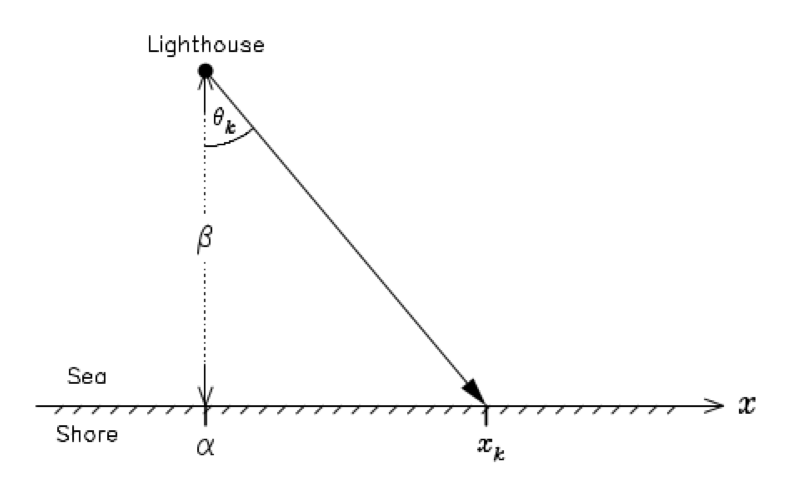

### Ex 2.1: simulating the lighthouse, i.e. generating the dataset of measurements

Your first task is to simulate this physical system, namely to generate the dataset $x_1, x_2, \dots, x_n$ given the true value $\alpha_*$.
To do this, we are going to randomly generate the angle $\theta_i$ at which a light pulse is emitted and we will compute the corresponding detection position $x_i$ as
$$
    x_i = \tan(\theta_i) + \alpha_* \, .
$$

**Task 7.** Write a function that takes as input $n$ and $\alpha_*$ and generates the dataset as a length-$n$ vector. Recall that each angle is independent from the others, and uniformly distributed in the interval $(-\pi/2, \pi/2)$.

In [ ]:
# Your code here:

**Task 8.** Using the change-of-variables formula, we can show that the detection position $x(\theta)$ has probability density
$$
\rho_x(x\mid\alpha_*)=\frac{1}{\pi\left(1+(x-\alpha_*)^2\right)}.
$$

Generate a dataset with $\alpha_*=20$ and $n=10\,000$, and compare its histogram with this theoretical density:

- Use `bins=range(-300,301)` to obtain 600 bins of width 1 between $-300$ and $300$.
- Set `density=True` to normalize the histogram as a probability density.
- Overlay the theoretical density $\rho_x$ in black.
- Set the displayed horizontal range to $-100\leq x\leq100$.
- Add a red vertical line at $x=\alpha_*$.
- Label both axes and add a legend.

In [ ]:
# Your code here:

**Task 9.** Answer the following questions.

1. Around which value of $x$ is the histogram peaked? Motivate your answer.
2. Which values of the angle $\theta$ correspond to the extreme values (the rare outliers)?

Your solution here:

### Ex 2.2: estimation of $\alpha_*$ through maximum likelihood

The previous exercise dealt with simulated data. We now want to consider the case of real measurements, for which you do not know the ground truth of the position. We will once more try to estimate the value of $\alpha_{\star}$ for this set of observations. For this part of the exercise, we denote by $n$ the number of observations in the dataset.

**Task 10.** 
The data are stored in the file "data-lighthouse.npy". Use ```np.load``` to load the file into a variable called ```dataset```. 
This will be your set of observations for this part of the exercise. Let's find the position of the lighthouse! 
How many measurements does it contain? Store the number of measurements in a variable called `n`.

In [ ]:
# Your code here:

Your solution here:

**Task 11.** Prove that the maximum likelihood estimator (MLE) $\hat{\alpha}$ is given by
$$
\hat{\alpha} = \arg\min_{\alpha} \sum_{i=1}^n \log (1+(x_i - \alpha)^2)
$$

Hints: 
- You can follow and adapt the many examples of MLE given in class to this specific problem. 
- It is useful to maximize the log-likelihood instead of the likelihood to convert products into sums (recall that logs do not alter the position of maxima). 
- Maximizing a function is equivalent to minimizing its negative.

Your solution here:

**Task 12.** From now on, we define

$$
f(\alpha, \{x_i\}_{i=1}^n) = \sum_{i=1}^n \log (1+(x_i - \alpha)^2)

$$

Write a function that takes as input $\alpha$ and the dataset (a length-$n$ vector) and computes $f(\alpha, \{x_i\}_{i=1}^n)$.

In [ ]:
# Your code here:

**Task 13.** Plot the function $f(\alpha, \{x_i\}_{i=1}^n)$ as a function of $\alpha$ using the given dataset. Plot it for $-10 < \alpha < 30$.
What can you deduce about the value of $\hat{\alpha}$ from the plot? Is the position of this lighthouse the same as that of the lighthouse in Ex 2.1?

In [ ]:
# Your code here:

Your solution here:

**Task 14.** We want to minimize $f$ to find the best value of $\alpha$. We will use gradient descent, updating $\alpha$ according to
$$
\alpha\leftarrow\alpha-\eta\,\frac{f'(\alpha, \{x_i\}_{i=1}^n)}{n},
$$
where $\eta$ is the learning rate and $n$ is the number of observations. The prime denotes a derivative with respect to $\alpha$. Dividing the gradient by $n$ makes the update less sensitive to the dataset size without changing the location of the minimum.

To begin, derive $f'(\alpha, \{x_i\}_{i=1}^n)$.

Your solution here:

**Task 15.** Implement a function that computes $f'(\alpha, \{x_i\}_{i=1}^n)$ for a given $\alpha$ and dataset. Then implement gradient descent using the update defined in **Task 14**, starting from $\alpha=0$ with learning rate $\eta=0.5$.

Stop when $|f'(\alpha, \{x_i\}_{i=1}^n)|/n<10^{-6}$ or after $10\,000$ iterations. Print the resulting estimate $\hat\alpha$ and whether the stopping tolerance was reached. Comment on your finding. In particular, what features of the plotted function suggest that gradient descent is a suitable method for this optimization problem? Is gradient descent mathematically guaranteed to find the global minimum of $f(\alpha,\{x_i\}_{i=1}^n)$?

In [ ]:
# Your code here:
def f_prime(alpha, dataset):
    # Your code here:
    raise NotImplementedError

def gradient_minimize(dataset, alpha0=0.0, eta=0.5,
                      tolerance=1e-6, max_iterations=10_000): 
    # Your code here:
    raise NotImplementedError  # Comment this out.
    return alpha, converged



Your solution here:

**Task 16.** 
Reproduce the plot you made in **Task 13**. 
Additionally, plot a vertical line at $x = \hat{\alpha}$ and add a legend.

In [ ]:
# Your code here:

**Task 17.** Compute the sample **mean** (the average of the measurements $x_i$) of the lighthouse measurements. Compute the **median** of the lighthouse measurements. Compare the mean and the median with the MLE $\hat\alpha$ from **Task 15**. Which estimates are closer to the "center" of the observed measurements? For this last point, it may be helpful to plot a histogram of the observations.

In [ ]:
# Your code here:

Your solution here:

**Task 18.** The lighthouse measurements follow a Cauchy distribution. Explain why the sample mean can be unreliable as an estimator of the lighthouse position. Consider the effect of extreme observations and whether the law of large numbers applies to this distribution.

Your solution here:

### Ex 2.3: How does the estimate change with the number of measurements?

We now return to simulated datasets. For this part of the exercise, the `data-lighthouse.npy` file is no longer needed. $n$ again denotes the dataset size.


**Task 19.** Consider a lighthouse at the known position $\alpha_*=20$. For each dataset size $n\in\{10,30,100,300,1000\}$, generate 200 independent datasets, each containing $n$ observations.

Compute the sample mean and the MLE for each dataset, using your gradient-descent function for the MLE, initializing `alpha0` (i.e. the initial value of gradient descent) at the sample median of the dataset.

Store the results in two NumPy arrays, `sample_means` and `mle_estimates`, each of shape `(5, 200)`, where each row corresponds to one value of $n$.

In [ ]:
alpha_true = 20.0
sample_sizes = [10, 30, 100, 300, 1000]
n_repeats = 200

# Your code here:
sample_means = ...
mle_estimates = ...

**Task 20.** Using the arrays from **Task 19**, compute the following quantities for each estimator and each value of $n$:

1. The standard deviation of the 200 estimates. 
2. The median absolute error: for each estimate $\hat\alpha$, compute its distance from the true position, $|\hat\alpha-\alpha_*|$, then take the median of these 200 absolute errors.

In total, you should obtain 10 standard deviations and 10 median absolute errors: five for the MLE and five for the sample mean, corresponding to the five values of $n$.

Plot the standard deviations against $n$ on one figure and the median absolute errors against $n$ on a second figure. In both plots, show the MLE in blue and the sample mean in orange. Label the axes and add legends. Use logarithmic scales on both axes for the first plot and on the x-axis for the second plot.

Does increasing $n$ improve both estimators (MLE and the mean) equally? Does the standard deviation of the sample mean provide a reliable measure of its estimation error in this case? Explain your answers in light of the previous tasks.

In [ ]:
# Your code here:

Your solution here:

## Sources and collaboration

Indicate any external sources (including AI tools) and anyone with whom you discussed this exercise. If none, state so explicitly.

Your solution here: